In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [69]:
ai_measurements_df = pd.read_excel('AI_Research_Technical_Outputs.xlsx')
non_zero_usage = ai_measurements_df[ai_measurements_df['Usage Rate'] > ai_measurements_df['Usage Rate'].quantile(0.75)]

ai_measurements_df['AIOE Percentile'] = ai_measurements_df['AIOE'].rank(pct=True)
theoretical_color = 'tab:blue'
observed_color = 'tab:orange'
dots_color = 'black'

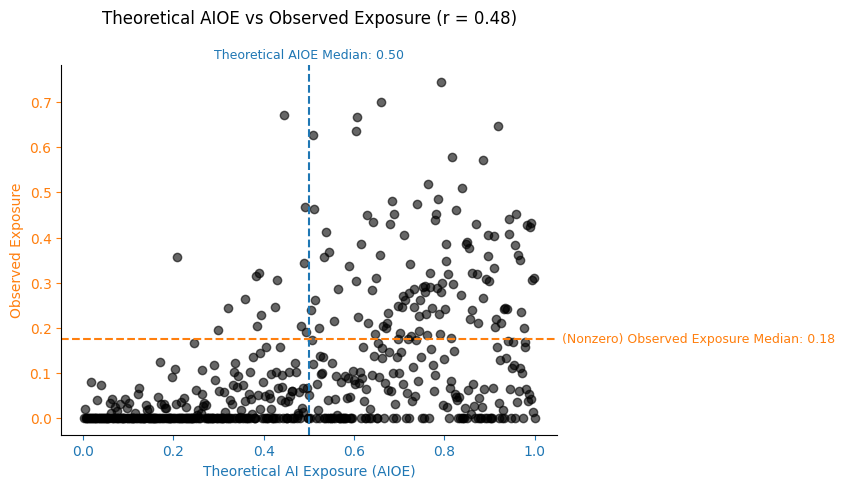

In [84]:
ax = plt.gca()

theoretical_median = ai_measurements_df['AIOE Percentile'].median()
observed_median = non_zero_usage['Observed Exposure'].median()

ax.scatter(
    ai_measurements_df['AIOE Percentile'],
    ai_measurements_df['Observed Exposure'],
    color=dots_color,
    alpha=0.6
)

ax.axvline(
    theoretical_median,
    color=theoretical_color,
    linestyle='--'
)

ax.axhline(
    observed_median,
    color=observed_color,
    linestyle='--'
)

# Label the horizontal median at the right edge
ax.text(
    1.01,
    observed_median,
    f'(Nonzero) Observed Exposure Median: {observed_median:.2f}',
    color=observed_color,
    transform=ax.get_yaxis_transform(),
    va='center',
    ha='left',
    fontsize=9
)

# Label the vertical median near the top
ax.text(
    theoretical_median,
    1.01,
    f'Theoretical AIOE Median: {theoretical_median:.2f}',
    color=theoretical_color,
    transform=ax.get_xaxis_transform(),
    va='bottom',
    ha='center',
    fontsize=9
)

ax.spines[['top', 'right']].set_visible(False)

plt.xlabel('Theoretical AI Exposure (AIOE)', color='tab:blue')
plt.ylabel('Observed Exposure', color='tab:orange')

plt.tick_params(axis='x', colors='tab:blue')
plt.tick_params(axis='y', colors='tab:orange')

correlation = ai_measurements_df[
    ['AIOE Percentile', 'Observed Exposure']
].corr().iloc[0, 1]

plt.title(
    f'Theoretical AIOE vs Observed Exposure (r = {correlation:.2f})',
    pad=30
)
plt.show()

# RQ3
Are higher AIOE scores associated with higher independently measured Claude usage intensity (if a valid usage denominator exists)?

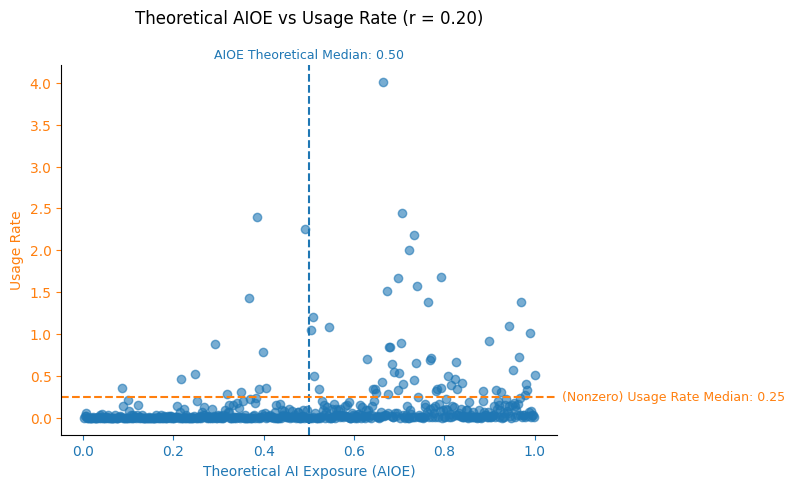

In [86]:
ax = plt.gca()

theoretical_median = ai_measurements_df['AIOE Percentile'].median()
observed_median = non_zero_usage['Usage Rate'].median()

ax.scatter(
    ai_measurements_df['AIOE Percentile'],
    ai_measurements_df['Usage Rate'],
    color='tab:blue',
    alpha=0.6
)

ax.axvline(
    theoretical_median,
    color=theoretical_color,
    linestyle='--'
)

ax.axhline(
    observed_median,
    color=observed_color,
    linestyle='--'
)

# Label the horizontal median at the right edge
ax.text(
    1.01,
    observed_median,
    f'(Nonzero) Usage Rate Median: {observed_median:.2f}',
    color=observed_color,
    transform=ax.get_yaxis_transform(),
    va='center',
    ha='left',
    fontsize=9
)

# Label the vertical median near the top
ax.text(
    theoretical_median,
    1.01,
    f'AIOE Theoretical Median: {theoretical_median:.2f}',
    color=theoretical_color,
    transform=ax.get_xaxis_transform(),
    va='bottom',
    ha='center',
    fontsize=9
)

ax.spines[['top', 'right']].set_visible(False)

plt.xlabel('Theoretical AI Exposure (AIOE)', color='tab:blue')
plt.ylabel('Usage Rate', color='tab:orange')

plt.tick_params(axis='x', colors='tab:blue')
plt.tick_params(axis='y', colors='tab:orange')


correlation = ai_measurements_df[
    ['AIOE Percentile', 'Usage Rate']
].corr().iloc[0, 1]

plt.title(
    f'Theoretical AIOE vs Usage Rate (r = {correlation:.2f})',
    pad=30
)
plt.show()

# RQ 4
Is estimated occupational complementarity associated with augmentation share?

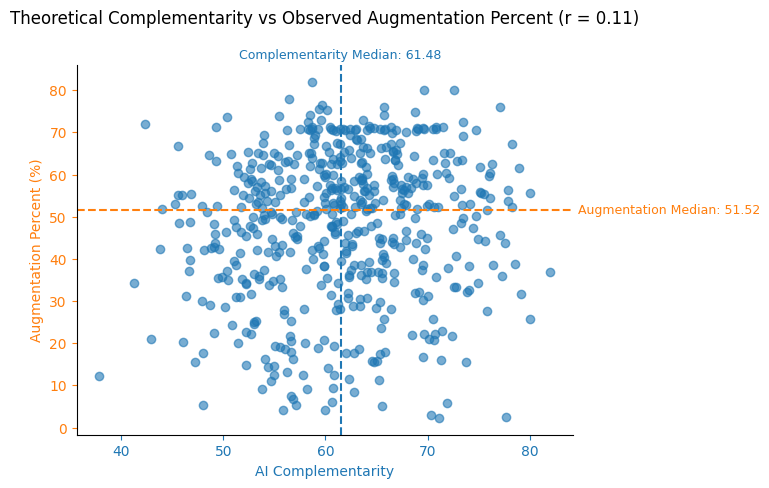

In [90]:
ax = plt.gca()

complementarity_median = ai_measurements_df['Complementarity'].median()
augmentation_median = ai_measurements_df['Augmentation Percent'].median()

ax.scatter(
    ai_measurements_df['Complementarity'],
    ai_measurements_df['Augmentation Percent'],
    color='tab:blue',
    alpha=0.6
)

ax.axvline(
    complementarity_median,
    color=theoretical_color,
    linestyle='--'
)

ax.axhline(
    augmentation_median,
    color=observed_color,
    linestyle='--'
)

# Label the horizontal median at the right edge
ax.text(
    1.01,
    augmentation_median,
    f'Augmentation Median: {augmentation_median:.2f}',
    color=observed_color,
    transform=ax.get_yaxis_transform(),
    va='center',
    ha='left',
    fontsize=9
)

# Label the vertical median near the top
ax.text(
    complementarity_median,
    1.01,
    f'Complementarity Median: {complementarity_median:.2f}',
    color=theoretical_color,
    transform=ax.get_xaxis_transform(),
    va='bottom',
    ha='center',
    fontsize=9
)

ax.spines[['top', 'right']].set_visible(False)

plt.xlabel('AI Complementarity', color='tab:blue')
plt.ylabel('Augmentation Percent (%)', color='tab:orange')

plt.tick_params(axis='x', colors='tab:blue')
plt.tick_params(axis='y', colors='tab:orange')

correlation = ai_measurements_df[
    ['Complementarity', 'Augmentation Percent']
].corr().iloc[0, 1]

plt.title(
    f'Theoretical Complementarity vs Observed Augmentation Percent (r = {correlation:.2f})',
    pad=30
)
plt.show()

# RQ 5
Is usage intensity associated with automation share?

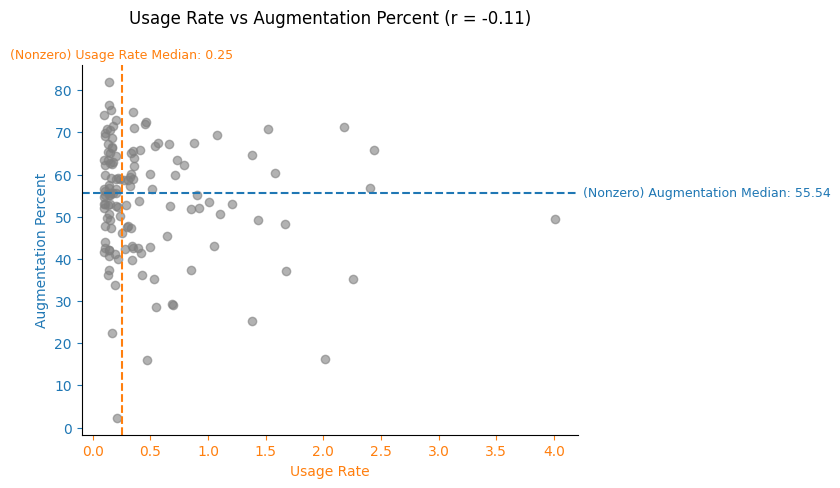

In [89]:
ax = plt.gca()

usage_median = non_zero_usage['Usage Rate'].median()
augmentation_median = non_zero_usage['Augmentation Percent'].median()

ax.scatter(
    non_zero_usage['Usage Rate'],
    non_zero_usage['Augmentation Percent'],
    color='gray',
    alpha=0.6
)

ax.axvline(
    usage_median,
    color=observed_color,
    linestyle='--'
)

ax.axhline(
    augmentation_median,
    color=theoretical_color,
    linestyle='--'
)

# Label the horizontal median at the right edge
ax.text(
    1.01,
    augmentation_median,
    f'(Nonzero) Augmentation Median: {augmentation_median:.2f}',
    color=theoretical_color,
    transform=ax.get_yaxis_transform(),
    va='center',
    ha='left',
    fontsize=9
)

# Label the vertical median near the top
ax.text(
    usage_median,
    1.01,
    f'(Nonzero) Usage Rate Median: {usage_median:.2f}',
    color=observed_color,
    transform=ax.get_xaxis_transform(),
    va='bottom',
    ha='center',
    fontsize=9
)

ax.spines[['top', 'right']].set_visible(False)

plt.xlabel('Usage Rate', color=observed_color)
plt.ylabel('Augmentation Percent', color=theoretical_color)

plt.tick_params(axis='x', colors=observed_color)
plt.tick_params(axis='y', colors=theoretical_color)

correlation = non_zero_usage[
    ['Usage Rate', 'Augmentation Percent']
].corr().iloc[0, 1]

plt.title(
    f'Usage Rate vs Augmentation Percent (r = {correlation:.2f})',
    pad=30
)
plt.show()
